<a href="https://colab.research.google.com/github/elsewise21/Electricity-Consumption-Pattern-and-Anomaly-Detection/blob/main/Electricity_Consumption_Pattern_and_Anomaly_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Electricity Consumption Pattern and Anomaly Analysis

## Project Overview

This project investigates electricity consumption patterns across three distribution zones in Tetouan City, Morocco, using historical electricity consumption and weather data.

The analysis uses Python to explore consumption trends, compare statistical variation between zones, and identify unusual consumption readings.

## Question

Can historical electricity consumption data reveal recurring demand patterns and unusual consumption behaviour across the three distribution zones?

## Objectives

1. Compare average electricity consumption across the three zones.
2. Examine how consumption varies over time.
3. Identify unusual consumption readings.
4. Interpret the findings and discuss their potential significance.

 Tools Used

Python, Google Colab, Pandas, NumPy, Matplotlib and Seaborn.

In [18]:
!pip install ucimlrepo pandas numpy matplotlib seaborn

In [19]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Retrieve real electricity consumption data
dataset = fetch_ucirepo(id=849)

# Extract the data
df = dataset.data.features

# Display the first five observations
print(df.head())

# Examine dataset dimensions
print("\nDataset dimensions:", df.shape)

# Examine available variables
print("\nDataset information:")
print(df.info())

        DateTime  Temperature  Humidity  Wind Speed  general diffuse flows  \
0  1/1/2017 0:00        6.559      73.8       0.083                  0.051   
1  1/1/2017 0:10        6.414      74.5       0.083                  0.070   
2  1/1/2017 0:20        6.313      74.5       0.080                  0.062   
3  1/1/2017 0:30        6.121      75.0       0.083                  0.091   
4  1/1/2017 0:40        5.921      75.7       0.081                  0.048   

   diffuse flows  
0          0.119  
1          0.085  
2          0.100  
3          0.096  
4          0.085  

Dataset dimensions: (52416, 6)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   DateTime               52416 non-null  object 
 1   Temperature            52416 non-null  float64
 2   Humidity               52416 non-null  flo

In [20]:
# Check column names
print("COLUMNS:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDATA INFORMATION:")
print(df.info())

# Check missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# Statistical summary
print("\nSTATISTICAL SUMMARY:")
print(df.describe().round(2))


COLUMNS:
['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows']

DATA INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   DateTime               52416 non-null  object 
 1   Temperature            52416 non-null  float64
 2   Humidity               52416 non-null  float64
 3   Wind Speed             52416 non-null  float64
 4   general diffuse flows  52416 non-null  float64
 5   diffuse flows          52416 non-null  float64
dtypes: float64(5), object(1)
memory usage: 2.4+ MB
None

MISSING VALUES:
DateTime                 0
Temperature              0
Humidity                 0
Wind Speed               0
general diffuse flows    0
diffuse flows            0
dtype: int64

STATISTICAL SUMMARY:
       Temperature  Humidity  Wind Speed  general diffuse flows  diffuse flows
co

In [21]:
# Extract features and targets separately
features = dataset.data.features
targets = dataset.data.targets

# Combine them into one DataFrame
df = pd.concat([features, targets], axis=1)

# Inspect column names
print(df.columns.tolist())

['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2  Power Consumption', 'Zone 3  Power Consumption']


AVERAGE CONSUMPTION BY ZONE:
Zone 1 Power Consumption     32344.97
Zone 2  Power Consumption    21042.51
Zone 3  Power Consumption    17835.41
dtype: float64


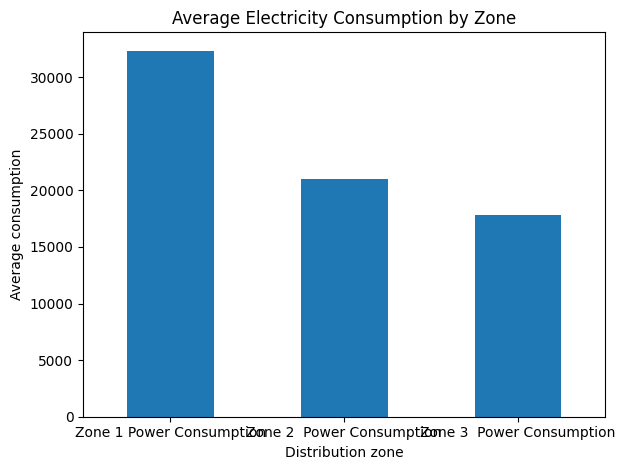

In [22]:
zones = [
    'Zone 1 Power Consumption',
    'Zone 2  Power Consumption',
    'Zone 3  Power Consumption'
]

average_consumption = df[zones].mean()

print("AVERAGE CONSUMPTION BY ZONE:")
print(average_consumption.round(2))

average_consumption.plot(
    kind='bar',
    title='Average Electricity Consumption by Zone',
    ylabel='Average consumption',
    xlabel='Distribution zone'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
# Calculate variability in each zone

statistics = pd.DataFrame({
    'Mean': df[zones].mean(),
    'Median': df[zones].median(),
    'Standard Deviation': df[zones].std(),
    'Minimum': df[zones].min(),
    'Maximum': df[zones].max()
})

print(statistics.round(2))

                               Mean    Median  Standard Deviation   Minimum  \
Zone 1 Power Consumption   32344.97  32265.92             7130.56  13895.70   
Zone 2  Power Consumption  21042.51  20823.17             5201.47   8560.08   
Zone 3  Power Consumption  17835.41  16415.12             6622.17   5935.17   

                            Maximum  
Zone 1 Power Consumption   52204.40  
Zone 2  Power Consumption  37408.86  
Zone 3  Power Consumption  47598.33  


In [24]:
# Calculate coefficient of variation
cv = (df[zones].std() / df[zones].mean()) * 100

print("COEFFICIENT OF VARIATION:")
print(cv.round(2).astype(str) + "%")

COEFFICIENT OF VARIATION:
Zone 1 Power Consumption     22.05%
Zone 2  Power Consumption    24.72%
Zone 3  Power Consumption    37.13%
dtype: object


In [25]:
print(df.columns.tolist())
print(df.head())
print(df.dtypes)


['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2  Power Consumption', 'Zone 3  Power Consumption']
        DateTime  Temperature  Humidity  Wind Speed  general diffuse flows  \
0  1/1/2017 0:00        6.559      73.8       0.083                  0.051   
1  1/1/2017 0:10        6.414      74.5       0.083                  0.070   
2  1/1/2017 0:20        6.313      74.5       0.080                  0.062   
3  1/1/2017 0:30        6.121      75.0       0.083                  0.091   
4  1/1/2017 0:40        5.921      75.7       0.081                  0.048   

   diffuse flows  Zone 1 Power Consumption  Zone 2  Power Consumption  \
0          0.119               34055.69620                16128.87538   
1          0.085               29814.68354                19375.07599   
2          0.100               29128.10127                19006.68693   
3          0.096               28228.86076               

In [26]:
df['DateTime'] = pd.to_datetime(df['DateTime'])

df['Hour'] = df['DateTime'].dt.hour
df['Day'] = df['DateTime'].dt.day_name()
df['Date'] = df['DateTime'].dt.date

print(df[['DateTime', 'Hour', 'Day', 'Date']].head())

             DateTime  Hour     Day        Date
0 2017-01-01 00:00:00     0  Sunday  2017-01-01
1 2017-01-01 00:10:00     0  Sunday  2017-01-01
2 2017-01-01 00:20:00     0  Sunday  2017-01-01
3 2017-01-01 00:30:00     0  Sunday  2017-01-01
4 2017-01-01 00:40:00     0  Sunday  2017-01-01


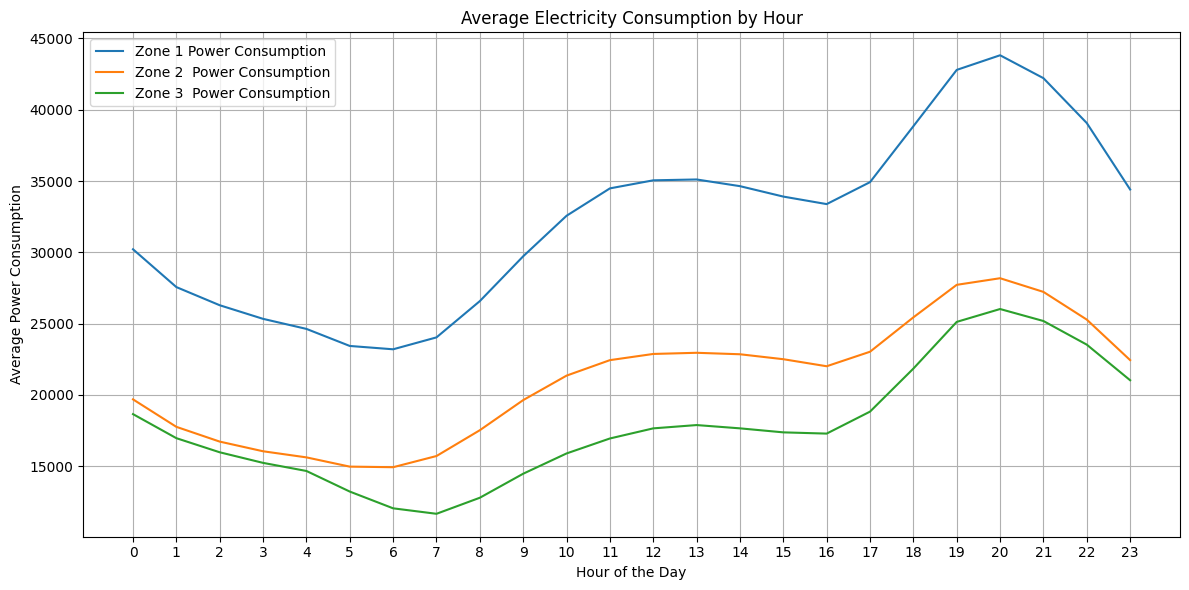

In [27]:
hourly_consumption = df.groupby('Hour')[zones].mean()

hourly_consumption.plot(
    figsize=(12, 6),
    title='Average Electricity Consumption by Hour',
    xlabel='Hour of the Day',
    ylabel='Average Power Consumption'
)

plt.xticks(range(0, 24))
plt.grid()
plt.tight_layout()
plt.show()

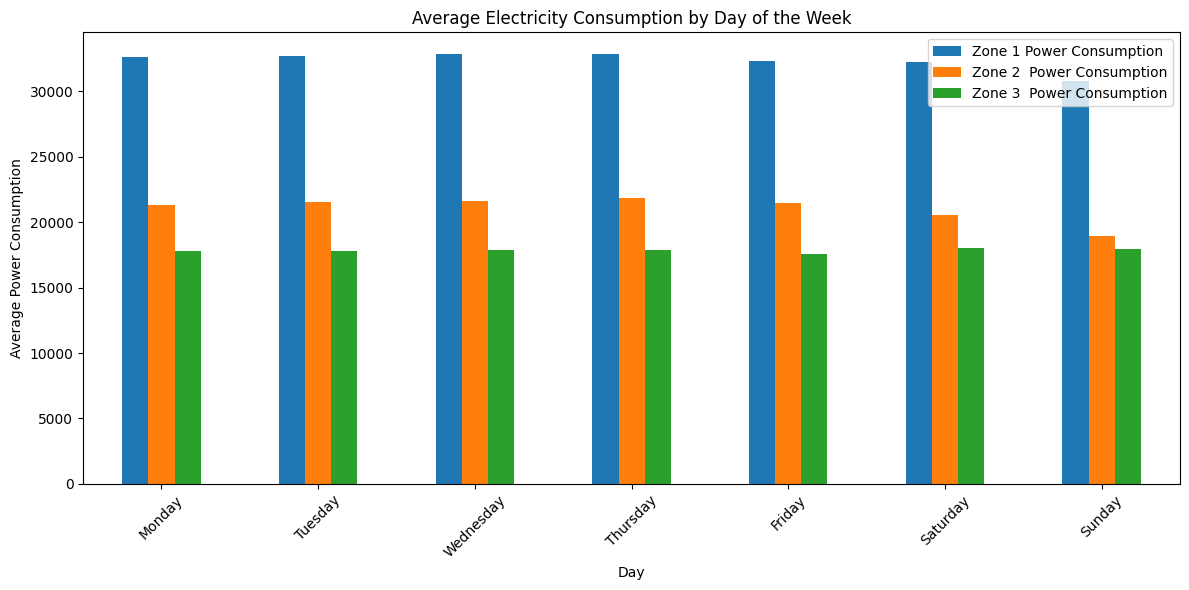

In [28]:
daily_consumption = df.groupby('Day')[zones].mean()

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_consumption = daily_consumption.reindex(day_order)

daily_consumption.plot(
    kind='bar',
    figsize=(12, 6),
    title='Average Electricity Consumption by Day of the Week',
    ylabel='Average Power Consumption',
    xlabel='Day'
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
# Calculate the normal consumption level for each day and hour
for zone in zones:
    df[f'{zone}_Expected'] = df.groupby(
        ['Day', 'Hour']
    )[zone].transform('mean')

    df[f'{zone}_Std'] = df.groupby(
        ['Day', 'Hour']
    )[zone].transform('std')

    # Calculate how unusual each reading is
    df[f'{zone}_Zscore'] = (
        (df[zone] - df[f'{zone}_Expected']) /
        df[f'{zone}_Std']
    )

    # Flag readings more than 3 standard deviations away
    df[f'{zone}_Anomaly'] = (
        df[f'{zone}_Zscore'].abs() > 3
    )

# Count unusual readings in each zone
for zone in zones:
    print(
        zone,
        ':',
        df[f'{zone}_Anomaly'].sum(),
        'unusual readings'
    )

Zone 1 Power Consumption : 131 unusual readings
Zone 2  Power Consumption : 57 unusual readings
Zone 3  Power Consumption : 99 unusual readings


In [30]:
for zone in zones:
    print('\n', zone)

    anomalies = df[df[f'{zone}_Anomaly']].copy()

    anomalies['Deviation'] = df[f'{zone}_Zscore'].abs()

    print(
        anomalies.nlargest(5, 'Deviation')[
            ['DateTime', zone, f'{zone}_Expected',
             f'{zone}_Zscore']
        ].round(2)
    )



 Zone 1 Power Consumption
                 DateTime  Zone 1 Power Consumption  \
15769 2017-04-20 12:10:00                  16814.98   
15770 2017-04-20 12:20:00                  17794.62   
25458 2017-06-26 19:00:00                  27388.61   
25602 2017-06-27 19:00:00                  28660.13   
25459 2017-06-26 19:10:00                  28062.52   

       Zone 1 Power Consumption_Expected  Zone 1 Power Consumption_Zscore  
15769                           35897.49                            -5.35  
15770                           35897.49                            -5.07  
25458                           43254.94                            -4.36  
25602                           43370.35                            -4.21  
25459                           43254.94                            -4.18  

 Zone 2  Power Consumption
                 DateTime  Zone 2  Power Consumption  \
29435 2017-07-24 09:50:00                   31120.25   
29434 2017-07-24 09:40:00                   30

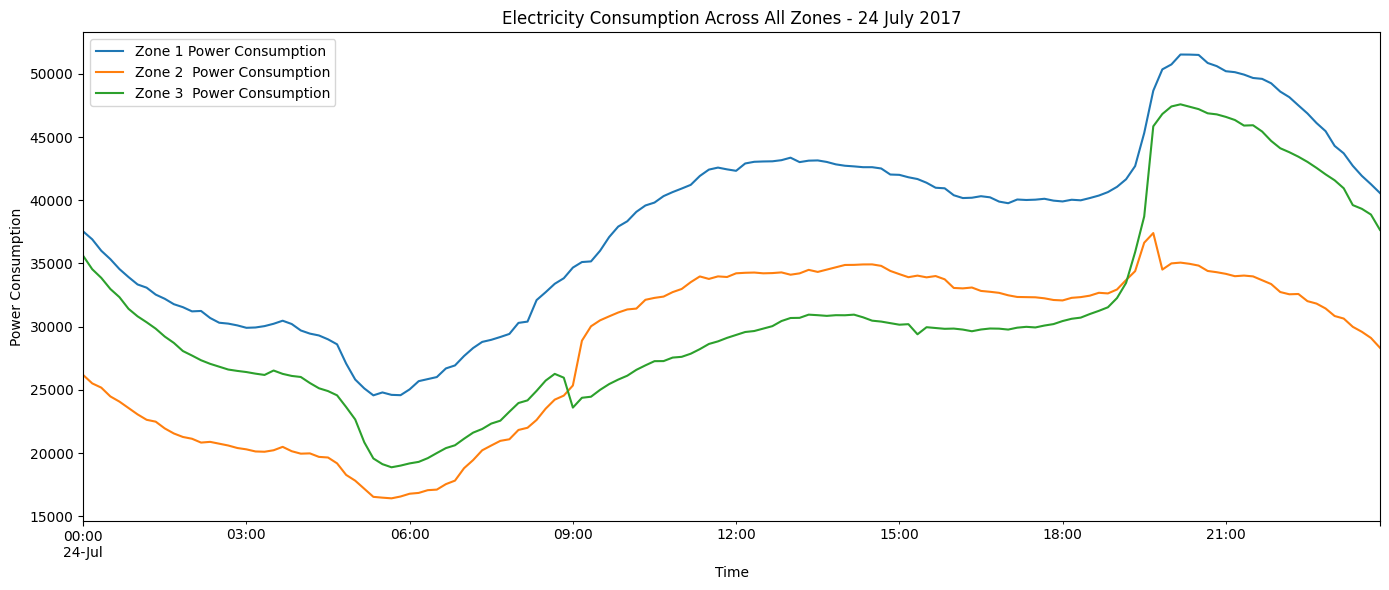

In [31]:
selected_date = '2017-07-24'

day_data = df[
    df['DateTime'].dt.date ==
    pd.to_datetime(selected_date).date()
]

day_data.set_index('DateTime')[zones].plot(
    figsize=(14, 6),
    title='Electricity Consumption Across All Zones - 24 July 2017',
    xlabel='Time',
    ylabel='Power Consumption'
)

plt.tight_layout()
plt.show()

In [32]:
for zone in zones:
    flag = df[f'{zone}_Anomaly']
    zscore = df[f'{zone}_Zscore']

    # Identify consecutive groups of anomalous readings
    groups = (~flag).cumsum()

    events = df[flag].groupby(groups[flag]).agg(
        Start=('DateTime', 'min'),
        End=('DateTime', 'max'),
        Readings=('DateTime', 'count')
    )

    events['Duration (minutes)'] = events['Readings'] * 10

    events['Largest deviation'] = (
        zscore[flag].abs().groupby(groups[flag]).max()
    )

    events['Direction'] = (
        zscore[flag].groupby(groups[flag]).mean()
        .apply(lambda x: 'High' if x > 0 else 'Low')
    )

    print(f'\n{zone}')
    print(
        events.sort_values(
            'Readings', ascending=False
        ).head(5).round(2)
    )


Zone 1 Power Consumption
                                               Start                 End  \
Zone 1 Power Consumption_Anomaly                                           
24574                            2017-06-21 01:00:00 2017-06-21 03:20:00   
15792                            2017-04-20 16:50:00 2017-04-20 18:30:00   
24700                            2017-06-22 01:00:00 2017-06-22 02:40:00   
24959                            2017-06-24 01:00:00 2017-06-24 02:30:00   
24831                            2017-06-23 01:30:00 2017-06-23 02:30:00   

                                  Readings  Duration (minutes)  \
Zone 1 Power Consumption_Anomaly                                 
24574                                   15                 150   
15792                                   11                 110   
24700                                   11                 110   
24959                                   10                 100   
24831                                    7   

In [33]:
anomaly_cols = [f'{zone}_Anomaly' for zone in zones]

df['Number_of_Anomalous_Zones'] = (
    df[anomaly_cols].sum(axis=1)
)

print("Simultaneous anomaly readings:")
print(
    df['Number_of_Anomalous_Zones']
    .value_counts()
    .sort_index()
)

# Show timestamps where at least two zones were anomalous
simultaneous = df[
    df['Number_of_Anomalous_Zones'] >= 2
]

print("\nDates with simultaneous anomalies:")
print(
    simultaneous.groupby('Date')
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Simultaneous anomaly readings:
Number_of_Anomalous_Zones
0    52132
1      281
2        3
Name: count, dtype: int64

Dates with simultaneous anomalies:
Date
2017-06-26    3
dtype: int64


## Results and Findings

### 1. Average Electricity Consumption

Zone 1 recorded the highest average electricity consumption (32,344.97), followed by Zone 2 (21,042.51) and Zone 3 (17,835.41).

### 2. Relative Variation

The coefficient of variation showed that Zone 3 had the greatest relative variability at 37.13%, compared with 24.72% for Zone 2 and 22.05% for Zone 1.

### 3. Daily Consumption Pattern

All three zones experienced their highest average electricity consumption at approximately 20:00 (8 p.m.), indicating a shared evening demand peak.

### 4. Anomaly Detection

Using a statistical threshold of three standard deviations from the expected consumption for each day-of-week and hour combination, the analysis identified:

- Zone 1: 131 unusual readings.
- Zone 2: 57 unusual readings.
- Zone 3: 99 unusual readings.

Some unusual readings occurred in sustained periods. The longest detected event was in Zone 2 on 24 July 2017, lasting 45 consecutive readings.

### 5. Simultaneous Anomalies

Only three readings showed unusual consumption in two zones simultaneously. All occurred on 26 June 2017. No readings showed simultaneous anomalies across all three zones.

## Conclusion

The analysis revealed differences in average consumption, relative variability and unusual demand patterns across the three distribution zones. Although Zone 1 had the highest average consumption and the greatest number of detected anomalies, Zone 3 exhibited the greatest relative variability.

The findings demonstrate how basic statistical analysis and Python programming can be used to extract meaningful patterns from real-world data. The detected anomalies provide potential starting points for further investigation, although they do not independently establish the causes of unusual consumption.

## Limitations

- The analysis identifies statistical anomalies but does not establish their physical or operational causes.
- Differences in customer numbers and zone characteristics were not accounted for.
- The anomaly detection method uses a simple statistical threshold rather than a trained machine-learning model.
- Seasonal and other longer-term changes in electricity demand may influence the results.